# 11 · Attention and a Transformer Block

**Learning objectives**
1. Compute scaled dot-product attention with every shape tracked.
2. Explain the causal mask and why it is needed for next-token prediction.
3. Build a pre-norm residual block from layer normalization, attention, and a feed-forward network.

Modules: `src/transformer.py`, `src/activations.py` (softmax), `tests/test_transformer.py`.

This notebook goes beyond the original master list of ten notebooks. It is included because attention is the core of modern LLMs.

## 1. Attention

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

- $Q, K$: shape $(T, d_k)$. $V$: shape $(T, d_v)$.
- $QK^\top$: shape $(T, T)$. Entry $(i,j)$ scores how much token $i$ asks about token $j$.
- The softmax is applied row by row, so each row of weights sums to 1.
- Dividing by $\sqrt{d_k}$ keeps the score variance near 1 (Part 9 of the notes).

**Example.** Three tokens, $d_\text{model}=4$, $d_k=d_v=2$. Projections are simple so each value can be checked by hand.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

from transformer import attention

X = np.array([[1, 0, 1, 0], [0, 1, 0, 1], [1, 1, 0, 0]], dtype=float)   # (T=3, d_model=4)
WQ = np.array([[1, 0], [0, 1], [1, 0], [0, 1]], dtype=float)
WK = np.array([[0, 1], [1, 0], [0, 1], [1, 0]], dtype=float)
WV = np.array([[1, 1], [0, 1], [1, 0], [0, 0.5]], dtype=float)
Q, K, V = X @ WQ, X @ WK, X @ WV
print("Q shape", Q.shape, " K shape", K.shape, " V shape", V.shape)
out, A = attention(Q, K, V)
print("scores QK^T / sqrt(2) =\n", (Q @ K.T / np.sqrt(2)).round(4))
print("weights A =\n", A.round(4))
print("row sums:", A.sum(axis=1))
print("output shape:", out.shape, "\n", out.round(4))

Q shape (3, 2)  K shape (3, 2)  V shape (3, 2)
scores QK^T / sqrt(2) =
 [[0.     2.8284 1.4142]
 [2.8284 0.     1.4142]
 [1.4142 1.4142 1.4142]]
weights A =
 [[0.0454 0.7679 0.1867]
 [0.7679 0.0454 0.1867]
 [0.3333 0.3333 0.3333]]
row sums: [1. 1. 1.]
output shape: (3, 2) 
 [[0.2775 1.5707]
 [1.7225 1.2094]
 [1.     1.5   ]]


**Check by hand.** Token 1's score for token 2 is $Q_1\cdot K_2/\sqrt 2 = 4/\sqrt 2 \approx 2.8284$. Its output is the weighted average of the value vectors, dominated by token 2's value $(0, 1.5)$.

## 2. Causal mask

For next-token prediction, token $i$ must not see tokens after $i$. Setting those scores to $-\infty$ before the softmax gives them zero weight.

causal weights =
 [[1.     0.     0.    ]
 [0.9442 0.0558 0.    ]
 [0.3333 0.3333 0.3333]]
causal output =
 [[2.     1.    ]
 [1.8884 1.0279]
 [1.     1.5   ]]


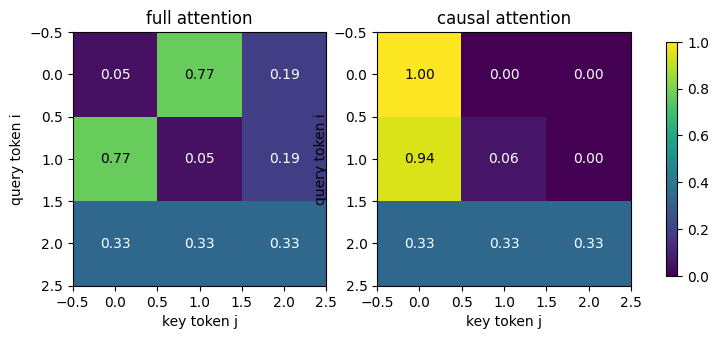

In [2]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

out_c, Ac = attention(Q, K, V, causal=True)
print("causal weights =\n", Ac.round(4))
print("causal output =\n", out_c.round(4))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, M, title in [(axes[0], A, "full attention"), (axes[1], Ac, "causal attention")]:
    im = ax.imshow(M, cmap="viridis", vmin=0, vmax=1)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", color="white" if M[i, j] < 0.5 else "black")
    ax.set_title(title); ax.set_xlabel("key token j"); ax.set_ylabel("query token i")
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

## 3. A pre-norm residual block

$$Y = X + \text{FFN}(\text{LayerNorm}(X))$$

Layer normalization acts on each token's features. The residual connection adds the input back, so gradients have a direct path (module 8 of the notes).

In [3]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

from transformer import layer_norm, residual_ffn_block, ffn

W1 = np.array([[0.5, -0.2, 0.1, 0.3], [0.2, 0.4, -0.1, 0.0], [-0.3, 0.1, 0.2, 0.5], [0.1, 0.0, 0.3, -0.2]])
W2 = np.array([[0.2, 0.1, 0.0, 0.0], [0.0, 0.3, 0.0, 0.0], [0.4, -0.1, 0.2, 0.0], [0.1, 0.2, 0.0, 0.1]])
print("layer norm of token 1:", layer_norm(X)[0].round(4))
print("FFN output of token 1:", ffn(layer_norm(X)[0:1], W1, W2)[0].round(4))
Y = residual_ffn_block(X, W1, W2)
print("block output shape:", Y.shape)
print(Y.round(4))

layer norm of token 1: [ 1. -1.  1. -1.]
FFN output of token 1: [0.14 0.19 0.02 0.1 ]
block output shape: (3, 4)
[[1.14 0.19 1.02 0.1 ]
 [0.02 1.16 0.   1.  ]
 [1.18 1.12 0.   0.  ]]


**Check by hand.** Token 1 normalizes to $(1,-1,1,-1)$. The ReLU hidden layer gives $(0,0,0.1,1.0)$, the FFN output is $(0.14, 0.19, 0.02, 0.10)$, and adding the residual gives $(1.14, 0.19, 1.02, 0.10)$. The layer-norm epsilon moves this by about $4\times10^{-6}$.

## 4. Multi-head shapes

With $d_\text{model}=8$ and 2 heads, each head has width $d_k = 4$. The split only reshapes the features; attention is then computed per head.

In [4]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

from transformer import split_heads
H = split_heads(np.arange(5 * 8, dtype=float).reshape(5, 8), n_heads=2)
print("per-head shape:", H.shape, "  (heads, tokens, d_head)")

per-head shape: (2, 5, 4)   (heads, tokens, d_head)


## 5. Interpretation

- Attention weights depend on the input. A fixed weight matrix cannot do this (the perceptron in notebook 02 has fixed weights).
- The causal mask turns the same operation into a next-token predictor.
- Residual connections and layer normalization keep deep stacks trainable (see notebook 08 on gradient products).

## 6. Exercises

1. Compute the causal output for token 2 by hand, using the weights shown above.
2. What changes if $d_k$ is 64 and the $\sqrt{d_k}$ scale is removed? Predict the effect on the softmax weights.
3. Stack two residual blocks. Write the shape of the output after each block.